# Prueba: agrupamiento propio de los quesos
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Cuaderno **de prueba**, separado de `trabajo_senasa_mq.ipynb`. En el k-medias general el queso casi no entra (hacen
falta humedad, grasa, proteína y cenizas), y los quesos que confirma el catálogo van ahora a una **rama propia** (humedad y
materia grasa, subtag por la clase de humedad del CAA). Acá se agrupan **los mismos quesos de esa rama** (los que tienen
materia grasa y sólidos totales; en Senasa + MQ: Senasa con `desc_familia = queso` y solo MQ únicamente si el rótulo
nombra la variedad; las MO no entran por MQ, ya están en Senasa), para ver si aparecen tipos de queso reales y, si
corresponde, proponer subtags `QUESO_<algo>`.

**Criterio de variables (lo fijó el usuario).**

* En queso, Senasa pide **materia grasa (MG)** y **sólidos totales (ST)**. La humedad (= 100 − ST) y la grasa en
  extracto seco (MGES = MG / ST × 100) son *funciones* de esos dos: no se usan como variables independientes junto con
  MG y ST (sería contar dos veces la misma información). **El espacio base tiene 2 dimensiones.**
* **NaCl, proteína y cenizas** son análisis de MQ (el NaCl es casi exclusivo de quesos). Van en un **nivel extendido**,
  solo para las muestras MQ que los tienen.

**Referencias para validar.** (1) El **subtipo** del rótulo (`desc_subtipo`: mozzarella, cremoso, reggianito…) y (2) la
**consistencia** del rótulo (`desc_consistencia`: baja / mediana / alta humedad, procesado, untable, mezcla; la arma
`src/compartido/catalogo.py` a partir de la variedad nombrada). Las dos son **independientes** de lo medido. (3) Las
**clases del CAA** (art. 605: humedad y MGES) son una función determinista de las mismas dos variables, así que el ARI
contra el CAA mide si los grupos naturales coinciden con los cortes legales: **no es una validación independiente**.

El código está en `src/clustering_quesos.py`; se regenera con `build_prueba_quesos.py`. Escribe solo en
`resultados/prueba_quesos/`. Semilla 42. Al final, el **veredicto**.

## 0 · Rutas, parámetros y lectura

In [1]:
import sys
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import adjusted_rand_score
import rutas as R
import clustering_quesos as Q
from datos_clase41 import SEMILLA, leer_senasa

warnings.filterwarnings("ignore", message=".*covariance matrix.*full rank.*")
warnings.filterwarnings("ignore", message=".*Determinant has increased.*")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
SALIDA = R.RESULTADOS / "prueba_quesos"; SALIDA.mkdir(parents=True, exist_ok=True)
PCT = 3                                   # corte de outliers por consenso (clase 46)
TAMANOS = (20, 30, 40, 50, 60)            # min_cluster_size de HDBSCAN
KS_KM, KS_GMM = range(2, 11), range(1, 9)
DPI = 150

S = leer_senasa()
quesos, _, _sin_confirmar, conteo = Q.rama_queso(S, True)   # misma poblacion que la rama del notebook unico: solo lo que confirma el catalogo, sin las MO
pd.Series(conteo, name="muestras").to_frame()

,muestras
quesos leídos,5915
con MG y ST,2892
excluidas: humedad + ST fuera de 100 ± 1,0
excluidas: MG > ST o fuera de rango,1
quedan,2891
solo MQ de familia queso sin confirmar por el rótulo (no entran),1128
"de ellas, con MG y ST",697


## 1 · Conteos
Quesos con MG y ST por origen. «Senasa completada con MQ»: muestra de Senasa a la que le faltaba MG o ST y lo completó
MQ (Senasa manda; MQ solo llena huecos). «solo MQ»: familia queso en `MQ encolumnado.xlsx` (que sale de
`mq_tipo_muestra.csv`, sin revisar a mano), que no está en Senasa y cuyo **rótulo nombra una variedad de queso**; las
solo MQ de familia queso que el rótulo no confirma (1128) quedan afuera, igual que en el notebook principal. Las MO de la
tabla ancha no entran por MQ (las que tienen código en Senasa entran por Senasa; una fila por Identificador). Exclusiones: humedad + ST fuera de 100 ± 1 donde
Senasa midió las dos (regla del proyecto; ningún queso con MG y ST la viola) y MG > ST (MGES > 100, imposible).

In [2]:
ext = quesos[Q.EXTRA].notna()
t = pd.DataFrame({"con MG y ST": quesos.groupby("origen").size(),
                  "+ NaCl": ext["nacl"].groupby(quesos["origen"]).sum(),
                  "+ proteína": ext["proteina"].groupby(quesos["origen"]).sum(),
                  "+ cenizas": ext["cenizas"].groupby(quesos["origen"]).sum(),
                  "+ NaCl y proteína": (ext["nacl"] & ext["proteina"]).groupby(quesos["origen"]).sum(),
                  "+ las tres": ext.all(axis=1).groupby(quesos["origen"]).sum(),
                  "con subtipo": quesos["subtipo"].notna().groupby(quesos["origen"]).sum(),
                  "con consistencia": quesos["consistencia"].notna().groupby(quesos["origen"]).sum()})
t.loc["total"] = t.sum()
t.astype(int)

,con MG y ST,+ NaCl,+ proteína,+ cenizas,+ NaCl y proteína,+ las tres,con subtipo,con consistencia
origen,,,,,,,,
Senasa,1627,0,0,0,0,0,1308,1614
Senasa completada con MQ,49,27,22,46,10,10,46,47
solo MQ,1215,478,423,61,357,8,1215,1211
total,2891,505,445,107,367,18,2569,2872


In [3]:
print("fuente del subtipo:", quesos["fuente_subtipo"].value_counts(dropna=False).to_dict())
sub = quesos["subtipo"].value_counts()
print(f"{sub.size} subtipos distintos; los 25 más frecuentes:")
display(pd.DataFrame({"muestras": sub.head(25),
                      "consistencia más común": [quesos.loc[quesos["subtipo"] == s, "consistencia"].mode().iat[0]
                                                 if quesos.loc[quesos["subtipo"] == s, "consistencia"].notna().any() else "-"
                                                 for s in sub.head(25).index]}).T)
pd.crosstab(quesos["consistencia"].fillna("sin dato"), quesos["caa_humedad"].fillna("-"), margins=True)

fuente del subtipo: {'rótulo': 2542, None: 322, 'mq_tipo_muestra': 27}
43 subtipos distintos; los 25 más frecuentes:


subtipo,AZUL,MOZZARELLA,CREMOSO,REGGIANITO,CHEDDAR,QUESO CREMA,PORT SALUT,PASTA HILADA,GOUDA,PARMESANO,FONTINA,PATEGRAS,SARDO,DANBO,GRUYERITO,HOLANDA,GRUYERE,PROVOLONE,CRIOLLO,TYBO,PRATO,RALLADO,SAINT PAULIN,EDAM,PROVOLETA
muestras,529,313,223,198,184,130,128,121,74,66,60,56,48,44,41,39,38,33,32,28,27,27,22,18,18
consistencia más común,mediana humedad,alta humedad,alta humedad,baja humedad,mediana humedad,untable,alta humedad,alta humedad,mediana humedad,baja humedad,mediana humedad,mediana humedad,baja humedad,mediana humedad,mediana humedad,mediana humedad,untable,baja humedad,mediana humedad,mediana humedad,mediana humedad,baja humedad,mediana humedad,mediana humedad,mediana humedad


caa_humedad,alta humedad,baja humedad,mediana humedad,muy alta humedad,All
consistencia,,,,,
alta humedad,606,0,115,101,822
baja humedad,0,491,36,0,527
mediana humedad,73,16,997,30,1116
mezcla,0,2,0,1,3
procesado,13,27,36,162,238
sin dato,1,3,11,4,19
untable,0,0,0,166,166
All,693,539,1195,464,2891


## 2 · Parametrización del espacio base
Las dos parametrizaciones posibles son equivalentes en información (una es función biyectiva de la otra), pero no en
geometría: el escalado y las distancias cambian.

* **(MG, ST)** es lo medido. Pero en queso MG y ST están muy correlacionadas (un queso más seco tiene más grasa por
  100 g): el eje principal mezcla «qué tan seco» con «qué tan graso».
* **(humedad, MGES)** es la del CAA: la humedad separa duro / semiduro / blando y la MGES dice qué tan graso es el
  queso *independientemente* de cuánta agua tenga. Casi no están correlacionadas: cada eje dice una cosa distinta.

Se elige **(humedad, MGES)**: ejes casi ortogonales, interpretables y en la escala de la norma. En la sección 3.4 se repite
todo en (MG, ST) para ver que el resultado no depende de la elección.

In [4]:
pd.DataFrame({"r de Pearson": [quesos[["mg", "st"]].corr().iat[0, 1], quesos[["humedad", "mges"]].corr().iat[0, 1]]},
             index=["MG vs ST", "humedad vs MGES"]).round(2)

,r de Pearson
MG vs ST,0.80
humedad vs MGES,0.09


## 3 · Nivel base: humedad y MGES, todos los quesos
### 3.1 · Outliers por consenso
`mejoras_clustering.outliers_consenso`: factor local (LOF, 50 vecinos), bosque de aislamiento y elipse, cada uno marca el
3 % de menor puntaje; outlier si lo marcan al menos 2 de 3. Todos los quesos son un solo grupo (el tag QUESO).

In [5]:
X_todas = Q.matriz(quesos, Q.BASE)
es_out, votos = Q.quitar_outliers(X_todas, pct=PCT)
base = quesos[~es_out].reset_index(drop=True)
print(f"outliers: {es_out.sum()} de {len(quesos)} ({100 * es_out.mean():.1f} %); quedan {len(base)}")
quesos.loc[es_out, ["Identificador", "origen", "mg", "st", "humedad", "mges", "subtipo"]].round(1).sort_values("humedad").head(12)

outliers: 81 de 2891 (2.8 %); quedan 2810


,Identificador,origen,mg,st,humedad,mges,subtipo
1626,MO-11426-01,Senasa,31.0,87.4,12.6,35.4,RALLADO
1572,MO-11086-01,Senasa,29.0,87.2,12.8,33.3,RALLADO
1444,MO-10182-01,Senasa,29.0,87.0,13.0,33.4,RALLADO
1588,MO-11195-01,Senasa,31.4,84.7,15.3,37.0,RALLADO
1284,MO-09473-01,Senasa,31.0,84.5,15.5,36.7,RALLADO
1500,MO-10629-01,Senasa,27.2,84.1,15.9,32.3,REGGIANITO
158,MO-03295-01,Senasa,17.2,80.2,19.8,21.5,NaN
1321,MO-09754-01,Senasa,25.9,80.1,19.9,32.3,RALLADO
107,MO-03109-01,Senasa,16.6,79.6,20.4,20.9,NaN
269,MO-03665-01,Senasa,17.2,79.1,20.9,21.7,NaN


### 3.2 · Los tres algoritmos
* **k-medias**: k por silueta máxima (2 a 10).
* **Mezcla de gaussianas** (covarianza completa, n_init 3): k por BIC mínimo (1 a 8).
* **HDBSCAN**: min_cluster_size 20 a 60. Se elige *sin mirar las referencias*: el número de grupos más frecuente en la
  grilla y, entre los que lo dan, el menor tamaño.

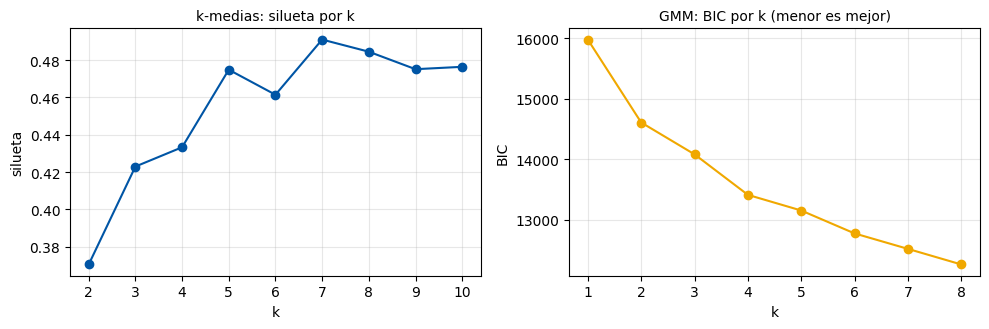

In [6]:
def correr(d, variables):
    # Los tres algoritmos sobre d[variables] escalado; etiquetas renumeradas por humedad media
    Z, _ = Q.escalar(Q.matriz(d, variables))
    km, k_km, sil, _ = Q.kmedias(Z, KS_KM)
    gm, k_gm, bic, mod = Q.mezcla(Z, KS_GMM)
    hd = Q.hdbscan_sensibilidad(Z, TAMANOS)
    m_hd, e_hd = Q.elegir_hdbscan(hd)
    h = d["humedad"].to_numpy()
    et = {f"k-medias (k = {k_km})": Q.ordenar(km, h), f"GMM (k = {k_gm}, BIC)": Q.ordenar(gm, h),
          f"HDBSCAN (min {m_hd})": Q.ordenar(e_hd, h)}
    return dict(Z=Z, et=et, sil=sil, bic=bic, hd=hd, m_hd=m_hd, gmm=mod, k_km=k_km, k_gm=k_gm)

def referencias(d):
    return {"subtipo": d["subtipo"], "consistencia": d["consistencia"], "CAA": d["caa"]}

def tabla(r, d, extra=True):
    filas = {n: Q.evaluar(r["Z"], e, referencias(d)) for n, e in r["et"].items()}
    if extra:   # referencia: la regla del CAA aplicada directamente (sin agrupar)
        for n, col in [("regla CAA humedad (4 clases)", "caa_humedad"), ("regla CAA humedad × MGES", "caa")]:
            e = pd.factorize(d[col])[0]
            filas[n] = Q.evaluar(r["Z"], e, referencias(d))
    return pd.DataFrame(filas).T

rb = correr(base, Q.BASE)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(list(rb["sil"]), list(rb["sil"].values()), "o-", color=Q.PALETA[0]); ax[0].set_xlabel("k"); ax[0].set_ylabel("silueta")
ax[0].set_title("k-medias: silueta por k", fontsize=10)
ax[1].plot(list(rb["bic"]), list(rb["bic"].values()), "o-", color=Q.PALETA[1]); ax[1].set_xlabel("k"); ax[1].set_ylabel("BIC")
ax[1].set_title("GMM: BIC por k (menor es mejor)", fontsize=10)
for a in ax: a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(SALIDA / "base_seleccion_k.png", dpi=DPI); plt.show()

El BIC de la mezcla baja hasta el máximo probado (k = 8) y, si se sigue, continúa bajando un poco (sección 3.5): la mezcla
aproxima una densidad continua, no prueba que haya ocho tipos. Por eso los subtags se proponen solo donde un componente
coincide con un tipo real (sección 5).

**Sensibilidad de HDBSCAN a min_cluster_size:**

In [7]:
filas = {}
for m, e in rb["hd"].items():
    f = Q.evaluar(rb["Z"], e, referencias(base))
    filas[m] = {k: f[k] for k in ["grupos", "ruido", "silueta", "silueta macro", "ARI subtipo", "ARI consistencia", "ARI CAA"]}
pd.DataFrame(filas).T.rename_axis("min_cluster_size").round(3)

,grupos,ruido,silueta,silueta macro,ARI subtipo,ARI consistencia,ARI CAA
min_cluster_size,,,,,,,
20,6.0,141.0,0.400,0.722,0.020,0.157,0.121
30,6.0,156.0,0.406,0.736,0.022,0.159,0.124
40,5.0,197.0,0.403,0.745,0.023,0.160,0.126
50,4.0,246.0,0.395,0.707,0.023,0.161,0.126
60,4.0,262.0,0.396,0.705,0.023,0.164,0.128


**Métricas y acuerdo con las referencias.** Silueta, Davies-Bouldin y Calinski-Harabasz sin el ruido; ARI y NMI contando
el ruido de HDBSCAN como un grupo más. Las dos últimas filas no son agrupamientos: son las clases del CAA aplicadas
directo, como vara para saber si agrupar agrega algo sobre el corte legal.

In [8]:
tb = tabla(rb, base)
tb.round(3)

,grupos,ruido,silueta,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,ARI subtipo,NMI subtipo,ARI consistencia,NMI consistencia,ARI CAA,NMI CAA
k-medias (k = 7),7.0,0.0,0.491,0.543,0.363,0.634,2727.574,0.283,0.445,0.307,0.422,0.406,0.598
"GMM (k = 8, BIC)",8.0,0.0,0.433,0.440,-0.395,1.176,1498.190,0.364,0.504,0.367,0.485,0.454,0.631
HDBSCAN (min 20),6.0,141.0,0.400,0.722,0.339,0.405,721.502,0.020,0.184,0.157,0.273,0.121,0.330
regla CAA humedad (4 clases),4.0,0.0,0.218,0.223,0.060,1.705,921.864,0.189,0.384,0.627,0.606,0.657,0.793
regla CAA humedad × MGES,12.0,0.0,0.233,0.292,0.000,0.974,1263.543,0.296,0.466,0.501,0.538,1.000,1.000


### 3.3 · Qué hay en cada cluster
Centroides en g/100 g (MGES en g/100 g de extracto seco); subtipo, consistencia y clase CAA mayoritarios con su pureza
(% sobre las muestras del cluster que tienen ese dato). Clusters numerados por humedad creciente.

In [9]:
for n, e in rb["et"].items():
    print(n); display(Q.describir(base, e))

k-medias (k = 7)


,muestras,mg,st,humedad,mges,subtipo mayoritario,% subtipo,con subtipo,consistencia mayoritario,% consistencia,con consistencia,CAA humedad mayoritario,% CAA humedad,CAA MGES mayoritario,% CAA MGES
cluster,,,,,,,,,,,,,,,
0,101,32.2,80.7,19.3,39.9,REGGIANITO,50.0,46,baja humedad,99.0,101,baja humedad,100.0,semigraso,100.0
1,586,29.9,66.2,33.8,45.1,REGGIANITO,34.0,487,baja humedad,69.0,583,baja humedad,69.0,graso,53.0
2,965,28.1,54.4,45.6,51.7,AZUL,49.0,934,mediana humedad,69.0,964,mediana humedad,66.0,graso,100.0
3,752,23.3,54.2,45.8,43.0,MOZZARELLA,40.0,706,alta humedad,59.0,741,mediana humedad,49.0,semigraso,79.0
4,88,9.5,36.6,63.4,26.4,PORT SALUT,55.0,87,alta humedad,59.0,88,muy alta humedad,95.0,semigraso,56.0
5,180,19.1,35.8,64.2,53.3,QUESO CREMA,37.0,155,procesado,54.0,179,muy alta humedad,98.0,graso,93.0
6,138,14.0,32.2,67.8,43.5,CHEDDAR,32.0,99,procesado,46.0,138,muy alta humedad,100.0,semigraso,62.0


GMM (k = 8, BIC)


,muestras,mg,st,humedad,mges,subtipo mayoritario,% subtipo,con subtipo,consistencia mayoritario,% consistencia,con consistencia,CAA humedad mayoritario,% CAA humedad,CAA MGES mayoritario,% CAA MGES
cluster,,,,,,,,,,,,,,,
0,97,32.4,81.2,18.8,39.9,RALLADO,50.0,42,baja humedad,99.0,97,baja humedad,100.0,semigraso,100.0
1,564,30.1,66.6,33.4,45.3,REGGIANITO,35.0,481,baja humedad,73.0,561,baja humedad,72.0,graso,54.0
2,653,29.4,56.6,43.4,51.9,AZUL,71.0,639,mediana humedad,96.0,652,mediana humedad,93.0,graso,100.0
3,786,23.8,54.9,45.1,43.3,MOZZARELLA,39.0,724,alta humedad,54.0,775,mediana humedad,54.0,semigraso,76.0
4,337,24.2,47.3,52.7,51.0,CREMOSO,65.0,320,alta humedad,85.0,337,alta humedad,83.0,graso,100.0
5,43,9.6,41.4,58.6,23.2,PORT SALUT,100.0,42,alta humedad,100.0,43,muy alta humedad,98.0,magro,88.0
6,116,14.9,36.1,63.9,40.7,QUESO CREMA,51.0,102,untable,46.0,115,muy alta humedad,90.0,semigraso,69.0
7,214,15.4,32.0,68.0,48.2,AZUL,32.0,164,procesado,45.0,214,muy alta humedad,100.0,graso,67.0


HDBSCAN (min 20)


,muestras,mg,st,humedad,mges,subtipo mayoritario,% subtipo,con subtipo,consistencia mayoritario,% consistencia,con consistencia,CAA humedad mayoritario,% CAA humedad,CAA MGES mayoritario,% CAA MGES
cluster,,,,,,,,,,,,,,,
0,95,32.5,81.2,18.8,40.0,REGGIANITO,50.0,40,baja humedad,99.0,95,baja humedad,100.0,semigraso,100.0
1,2321,26.9,57.1,42.9,47.3,AZUL,22.0,2148,mediana humedad,47.0,2306,mediana humedad,51.0,graso,64.0
2,45,9.7,41.4,58.6,23.3,PORT SALUT,100.0,44,alta humedad,100.0,45,muy alta humedad,96.0,magro,84.0
3,96,14.1,32.0,68.0,44.1,AZUL,38.0,72,procesado,36.0,96,muy alta humedad,100.0,semigraso,59.0
4,75,16.9,31.8,68.2,53.2,QUESO CREMA,66.0,67,untable,63.0,75,muy alta humedad,100.0,graso,100.0
5,37,8.6,28.7,71.3,29.8,QUESO CREMA,94.0,36,untable,92.0,37,muy alta humedad,100.0,semigraso,100.0
ruido,141,18.9,41.2,58.8,46.7,QUESO CREMA,21.0,107,procesado,41.0,140,muy alta humedad,75.0,semigraso,47.0


In [10]:
top = base["subtipo"].value_counts().head(15).index
for n, e in rb["et"].items():
    print(n, "· tabla cruzada con los 15 subtipos más frecuentes (columnas = cluster)")
    t = pd.crosstab(base["subtipo"].where(base["subtipo"].isin(top), "otros / sin dato"), np.where(e == -1, "ruido", e.astype(str)))
    display(t)

k-medias (k = 7) · tabla cruzada con los 15 subtipos más frecuentes (columnas = cluster)


col_0,0,1,2,3,4,5,6
subtipo,,,,,,,
AZUL,1,0,462,2,1,33,30
CHEDDAR,0,0,27,95,0,29,32
CREMOSO,0,0,199,8,1,14,1
DANBO,0,2,27,15,0,0,0
FONTINA,0,46,0,1,0,9,4
GOUDA,0,1,62,11,0,0,0
GRUYERITO,0,39,0,2,0,0,0
MOZZARELLA,0,0,28,284,1,0,0
PARMESANO,1,62,0,3,0,0,0


GMM (k = 8, BIC) · tabla cruzada con los 15 subtipos más frecuentes (columnas = cluster)


col_0,0,1,2,3,4,5,6,7
subtipo,,,,,,,,
AZUL,1,0,455,3,10,0,7,53
CHEDDAR,0,10,16,95,22,0,7,33
CREMOSO,0,0,4,3,209,0,7,0
DANBO,0,1,25,18,0,0,0,0
FONTINA,0,41,0,5,11,0,2,1
GOUDA,0,2,61,11,0,0,0,0
GRUYERITO,0,34,0,7,0,0,0,0
MOZZARELLA,0,0,19,280,12,0,2,0
PARMESANO,0,64,0,2,0,0,0,0


HDBSCAN (min 20) · tabla cruzada con los 15 subtipos más frecuentes (columnas = cluster)


col_0,0,1,2,3,4,5,ruido
subtipo,,,,,,,
AZUL,1,465,0,27,20,1,15
CHEDDAR,0,143,0,25,1,0,14
CREMOSO,0,215,0,0,0,0,8
DANBO,0,44,0,0,0,0,0
FONTINA,0,56,0,0,0,0,4
GOUDA,0,74,0,0,0,0,0
GRUYERITO,0,41,0,0,0,0,0
MOZZARELLA,0,309,0,0,0,0,4
PARMESANO,0,64,0,0,0,0,2


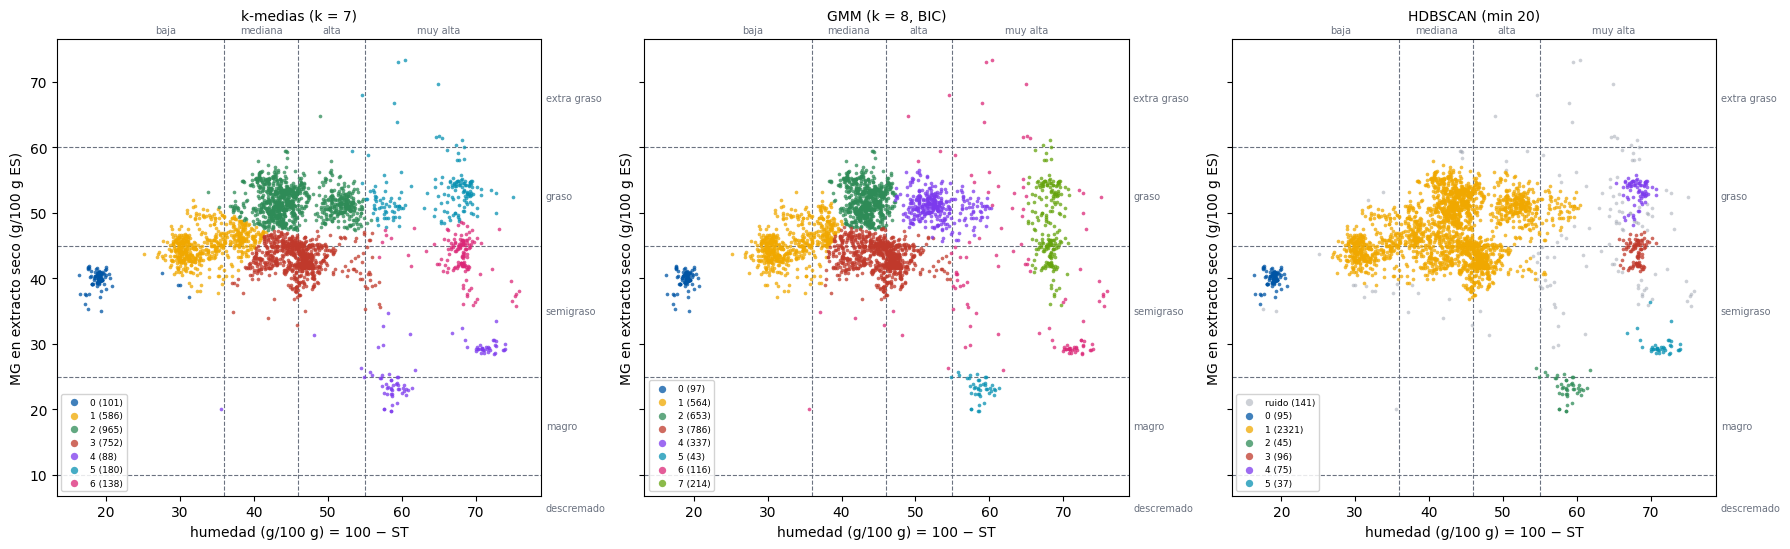

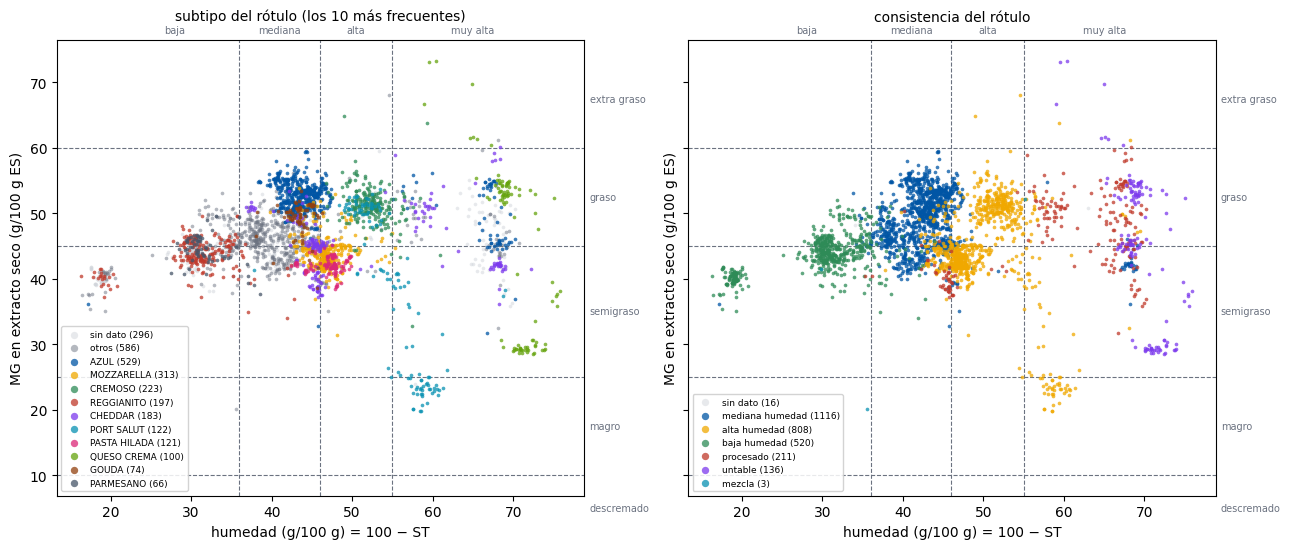

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5.6), sharex=True, sharey=True)
for a, (n, e) in zip(axs, rb["et"].items()):
    d = base.assign(cl=np.where(e == -1, "ruido", e.astype(str)))
    Q.dispersion_caa(a, d, "cl", n, max_cat=12, orden=sorted(set(d["cl"]) - {"ruido"}, key=int))
fig.tight_layout(); fig.savefig(SALIDA / "base_clusters.png", dpi=DPI); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 5.6), sharex=True, sharey=True)
Q.dispersion_caa(axs[0], base, "subtipo", "subtipo del rótulo (los 10 más frecuentes)", max_cat=10)
Q.dispersion_caa(axs[1], base, "consistencia", "consistencia del rótulo", max_cat=6)
fig.tight_layout(); fig.savefig(SALIDA / "base_referencias.png", dpi=DPI); plt.show()

### 3.4 · ¿Depende de la parametrización? Lo mismo en (MG, ST)
Mismas muestras (los mismos outliers), escaladas en (MG, ST). Se compara cada algoritmo con su par de la sección 3.2
(ARI entre las dos particiones: 1 = idénticas).

In [12]:
ra = correr(base, Q.BASE_ALT)
ta = tabla(ra, base, extra=False)
comp = pd.DataFrame({
    "k (H, MGES)": [rb["k_km"], rb["k_gm"], len(set(rb["et"][list(rb["et"])[2]]) - {-1})],
    "k (MG, ST)": [ra["k_km"], ra["k_gm"], len(set(ra["et"][list(ra["et"])[2]]) - {-1})],
    "ARI subtipo (H, MGES)": tb["ARI subtipo"].iloc[:3].values, "ARI subtipo (MG, ST)": ta["ARI subtipo"].values,
    "ARI consistencia (H, MGES)": tb["ARI consistencia"].iloc[:3].values, "ARI consistencia (MG, ST)": ta["ARI consistencia"].values,
    "ARI entre parametrizaciones": [adjusted_rand_score(a, b) for a, b in zip(rb["et"].values(), ra["et"].values())]},
    index=["k-medias", "GMM", "HDBSCAN"])
display(comp.round(3))
ta.round(3)

,"k (H, MGES)","k (MG, ST)","ARI subtipo (H, MGES)","ARI subtipo (MG, ST)","ARI consistencia (H, MGES)","ARI consistencia (MG, ST)",ARI entre parametrizaciones
k-medias,7,2,0.283,0.021,0.307,0.147,0.175
GMM,8,8,0.364,0.300,0.367,0.572,0.570
HDBSCAN,6,5,0.020,0.021,0.157,0.152,0.943


,grupos,ruido,silueta,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,ARI subtipo,NMI subtipo,ARI consistencia,NMI consistencia,ARI CAA,NMI CAA
k-medias (k = 2),2.0,0.0,0.611,0.608,0.604,0.535,3802.486,0.021,0.115,0.147,0.240,0.127,0.311
"GMM (k = 8, BIC)",8.0,0.0,0.443,0.489,0.165,0.727,4696.855,0.300,0.489,0.572,0.575,0.606,0.679
HDBSCAN (min 20),5.0,62.0,0.474,0.723,0.428,0.362,1330.210,0.021,0.179,0.152,0.281,0.119,0.330


### 3.5 · Estabilidad de la mezcla de gaussianas
La misma mezcla con otras semillas (k fijo en el elegido por BIC) y el BIC hasta k = 14 (solo para ver la forma).

In [13]:
from sklearn.mixture import GaussianMixture
k_gm = rb["k_gm"]; e0 = rb["et"][f"GMM (k = {k_gm}, BIC)"]
otras = {s: Q.ordenar(GaussianMixture(n_components=k_gm, n_init=3, random_state=s).fit(rb["Z"]).predict(rb["Z"]),
                      base["humedad"]) for s in range(SEMILLA + 1, SEMILLA + 6)}
print("ARI contra la semilla 42:", {s: round(adjusted_rand_score(e0, e), 2) for s, e in otras.items()})
bic_largo = {k: GaussianMixture(n_components=k, n_init=3, random_state=SEMILLA).fit(rb["Z"]).bic(rb["Z"]) for k in range(6, 15)}
print("BIC k = 6..14:", {k: round(v) for k, v in bic_largo.items()})

ARI contra la semilla 42: {43: 0.94, 44: 0.54, 45: 0.51, 46: 0.82, 47: 0.8}


BIC k = 6..14: {6: 12770, 7: 12514, 8: 12256, 9: 12014, 10: 12001, 11: 11994, 12: 12025, 13: 11914, 14: 11849}


## 4 · Nivel extendido: + NaCl, proteína y cenizas (solo MQ)
Cada variante usa solo las muestras con todas sus variables; para esas mismas muestras se corre también el nivel base
(humedad, MGES), así la comparación es justa. Outliers por consenso dentro de cada variante, con sus variables.

In [14]:
VARIANTES = {"+ NaCl": ["nacl"], "+ NaCl + proteína": ["nacl", "proteina"], "+ proteína": ["proteina"],
             "+ proteína + cenizas": ["proteina", "cenizas"]}
cols = ["silueta", "silueta macro", "ARI subtipo", "ARI consistencia", "ARI CAA"]
filas, res_ext = [], {}
for nombre, extra in VARIANTES.items():
    d = quesos.dropna(subset=extra).reset_index(drop=True)
    o, _ = Q.quitar_outliers(Q.matriz(d, Q.BASE + extra), pct=PCT)
    d = d[~o].reset_index(drop=True)
    for nivel, vs in [("base", Q.BASE), ("extendido", Q.BASE + extra)]:
        r = correr(d, vs)
        res_ext[(nombre, nivel)] = (d, r)
        for alg, e in r["et"].items():
            f = Q.evaluar(r["Z"], e, referencias(d))
            filas.append({"variante": nombre, "n": len(d), "nivel": nivel, "algoritmo": alg.split(" (")[0],
                          "k": f["grupos"], "ruido": f["ruido"], **{c: f[c] for c in cols}})
te = pd.DataFrame(filas).set_index(["variante", "n", "algoritmo", "nivel"]).sort_index(level=[0, 2, 3], sort_remaining=False)
te.round(3)

k  ruido  silueta  silueta macro  ARI subtipo  ARI consistencia  ARI CAA
variante             n   algoritmo nivel                                                                               
+ NaCl               494 GMM       base        8      0    0.471          0.583        0.325             0.302    0.505
                                   extendido   7      0    0.329          0.408        0.260             0.245    0.420
                         HDBSCAN   base        3     39    0.543          0.764        0.017             0.060    0.116
                                   extendido   2     89    0.438          0.640        0.034             0.077    0.102
                         k-medias  base        7      0    0.519          0.598        0.370             0.360    0.566
                                   extendido   6      0    0.426          0.490        0.284             0.287    0.432
+ NaCl + proteína    359 GMM       base        8      0    0.542          0.526        0.424             0.359    0.662
                                   extendido   7      0    0.331          0.455        0.375             0.306    0.500
                         HDBSCAN   base        2    176    0.621          0.619        0.170             0.122    0.282
                                   extendido   0    359      NaN            NaN        0.000             0.000    0.000
                         k-medias  base       10      0    0.595          0.602        0.497             0.416    0.712
                                   extendido   6      0    0.472          0.531        0.321             0.273    0.468
+ proteína           432 GMM       base        7      0    0.425          0.598        0.290             0.262    0.541
                                   extendido   8      0    0.491          0.541        0.427             0.339    0.622
                         HDBSCAN   base        2     27    0.638          0.748        0.012            -0.010    0.114
                                   extendido   3     21    0.554          0.739        0.041             0.075    0.170
                         k-medias  base        2      0    0.586          0.683        0.002            -0.065    0.085
                                   extendido  10      0    0.588          0.578        0.490             0.390    0.710
+ proteína + cenizas 74  GMM       base        5      0    0.540          0.678        0.028             0.175    0.158
                                   extendido   8      0    0.370          0.438        0.134             0.215    0.345
                         HDBSCAN   base        0     74      NaN            NaN        0.000             0.000    0.000
                                   extendido   0     74      NaN            NaN        0.000             0.000    0.000
                         k-medias  base        2      0    0.568          0.517        0.003             0.095    0.094
                                   extendido  10      0    0.437          0.525        0.148             0.384    0.385

**¿Por qué ayudan poco?** En queso, ST ≈ MG + proteína + cenizas (+ lactosa residual): la proteína queda casi determinada
por MG y ST. Y el NaCl acompaña a la humedad (los quesos duros están más salados). Lo nuevo que aportan es poco y, al
escalarlas, pesan lo mismo que humedad y MGES y diluyen la estructura.

In [15]:
d = quesos.dropna(subset=["proteina"])
r2 = LinearRegression().fit(d[["mg", "st"]], d["proteina"]).score(d[["mg", "st"]], d["proteina"])
d2 = quesos.dropna(subset=["nacl"])
print(f"R² de proteína ~ MG + ST: {r2:.2f} (n = {len(d)})")
print(f"r de Pearson NaCl vs humedad: {d2[['nacl', 'humedad']].corr().iat[0, 1]:.2f}; NaCl vs MGES: {d2[['nacl', 'mges']].corr().iat[0, 1]:.2f} (n = {len(d2)})")
d2.groupby(d2["consistencia"].fillna("sin dato"))["nacl"].describe().round(2)

R² de proteína ~ MG + ST: 0.85 (n = 445)
r de Pearson NaCl vs humedad: -0.63; NaCl vs MGES: 0.03 (n = 505)


,count,mean,std,min,25%,50%,75%,max
consistencia,,,,,,,,
alta humedad,232.0,1.01,0.45,0.00,0.75,0.96,1.31,2.26
baja humedad,83.0,2.26,0.44,1.09,1.98,2.19,2.48,3.85
mediana humedad,138.0,1.61,0.64,0.47,1.15,1.51,2.00,3.69
procesado,44.0,1.01,0.53,0.45,0.75,0.80,1.18,3.20
sin dato,3.0,0.42,0.59,0.07,0.08,0.09,0.60,1.10
untable,5.0,0.67,0.05,0.60,0.65,0.67,0.72,0.72


,muestras,mg,st,humedad,mges,nacl,proteina,subtipo mayoritario,% subtipo,con subtipo,consistencia mayoritario,% consistencia,con consistencia,CAA humedad mayoritario,% CAA humedad,CAA MGES mayoritario,% CAA MGES,subtag,criterio
cluster,,,,,,,,,,,,,,,,,,,
0,14,32.5,80.9,19.1,40.1,2.4,36.4,REGGIANITO,100.0,14,baja humedad,100.0,14,baja humedad,100.0,semigraso,100.0,QUESO,NaN
1,100,26.4,60.1,39.9,44.0,1.3,28.3,MOZZARELLA,36.0,100,mediana humedad,37.0,100,mediana humedad,41.0,semigraso,68.0,QUESO,NaN
2,53,27.5,57.2,42.8,48.3,1.8,24.2,CHEDDAR,21.0,52,mediana humedad,83.0,52,mediana humedad,89.0,graso,75.0,QUESO_SEMIDURO,consistencia
3,35,21.7,52.0,48.0,41.6,1.1,21.0,CHEDDAR,49.0,35,procesado,51.0,35,mediana humedad,49.0,semigraso,86.0,QUESO,NaN
4,98,24.6,48.0,52.0,51.2,1.2,18.3,CREMOSO,68.0,98,alta humedad,100.0,98,alta humedad,95.0,graso,100.0,QUESO_PASTA_BLANDA,consistencia
5,29,9.9,41.8,58.2,23.6,0.6,26.7,PORT SALUT,100.0,29,alta humedad,100.0,29,muy alta humedad,93.0,magro,76.0,QUESO_PORT_SALUT,subtipo
6,30,17.5,32.2,67.8,54.3,0.7,6.9,AZUL,57.0,30,procesado,77.0,30,muy alta humedad,100.0,graso,97.0,QUESO_PROCESADO,consistencia


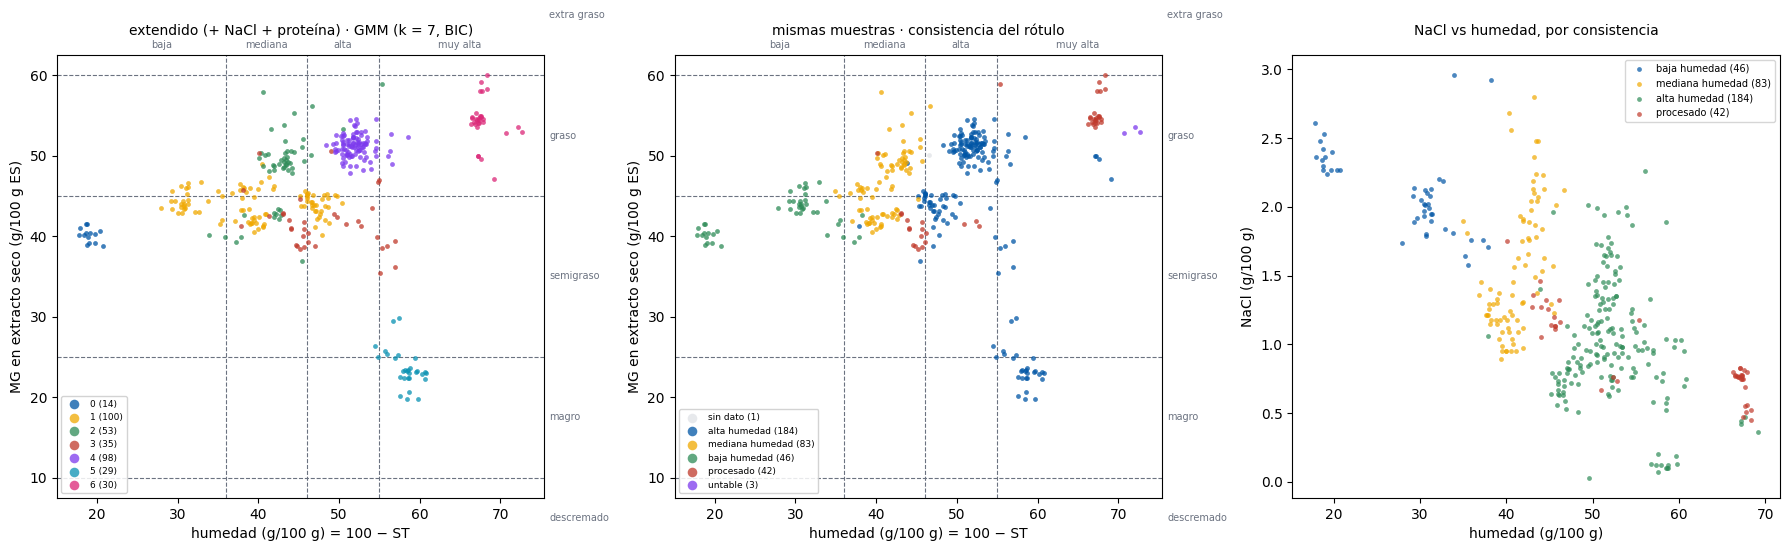

In [16]:
d_ext, r_ext = res_ext[("+ NaCl + proteína", "extendido")]
n_gm = [n for n in r_ext["et"] if n.startswith("GMM")][0]
e_ext = r_ext["et"][n_gm]
desc_ext = Q.describir(d_ext, e_ext, cols=("mg", "st", "humedad", "mges", "nacl", "proteina"))
display(desc_ext.join(Q.proponer_subtags(desc_ext)[["subtag", "criterio"]]).fillna({"subtag": "QUESO"}))
fig, axs = plt.subplots(1, 3, figsize=(18, 5.6))
de = d_ext.assign(cl=e_ext.astype(str))
Q.dispersion_caa(axs[0], de, "cl", f"extendido (+ NaCl + proteína) · {n_gm}", max_cat=12, orden=sorted(set(de["cl"]), key=int), s=12)
Q.dispersion_caa(axs[1], d_ext, "consistencia", "mismas muestras · consistencia del rótulo", max_cat=6, s=12)
for i, cons in enumerate(["baja humedad", "mediana humedad", "alta humedad", "procesado"]):
    sel = d_ext["consistencia"] == cons
    axs[2].scatter(d_ext.loc[sel, "humedad"], d_ext.loc[sel, "nacl"], s=12, alpha=0.7, c=Q.PALETA[i], lw=0, label=f"{cons} ({sel.sum()})")
axs[2].set_xlabel("humedad (g/100 g)"); axs[2].set_ylabel("NaCl (g/100 g)"); axs[2].legend(fontsize=7)
axs[2].set_title("NaCl vs humedad, por consistencia", fontsize=10, pad=14)
fig.tight_layout(); fig.savefig(SALIDA / "extendido.png", dpi=DPI); plt.show()

## 5 · Subtags
Regla (`clustering_quesos.proponer_subtags`): un cluster lleva subtag solo si corresponde a un tipo real, en este orden:
1. **subtipo** del rótulo con pureza ≥ 70 % (con ≥ 20 muestras con subtipo, que sean al menos la mitad del cluster) →
   `QUESO_<SUBTIPO>`;
2. si no, **consistencia** del rótulo con pureza ≥ 70 % → `QUESO_DURO`, `QUESO_SEMIDURO`, `QUESO_PASTA_BLANDA`,
   `QUESO_PROCESADO`, `QUESO_UNTABLE`;
3. si no, **clase de humedad del CAA** con pureza ≥ 70 % *y* la consistencia del rótulo compatible en ≥ 50 % (la clase
   legal sola no alcanza: sale de las mismas dos variables).

Se aplica a los tres algoritmos del nivel base; para el CSV se usa la **mezcla de gaussianas** (ver veredicto).

In [17]:
props = {}
for n, e in rb["et"].items():
    desc = Q.describir(base, e)
    p = Q.proponer_subtags(desc)
    props[n] = p
    print(n); display(desc[["muestras", "humedad", "mges", "subtipo mayoritario", "% subtipo", "consistencia mayoritario",
                            "% consistencia", "CAA humedad mayoritario", "% CAA humedad"]].join(p[["subtag", "criterio"]]).fillna({"subtag": "QUESO"}))

k-medias (k = 7)


,muestras,humedad,mges,subtipo mayoritario,% subtipo,consistencia mayoritario,% consistencia,CAA humedad mayoritario,% CAA humedad,subtag,criterio
cluster,,,,,,,,,,,
0,101,19.3,39.9,REGGIANITO,50.0,baja humedad,99.0,baja humedad,100.0,QUESO_DURO,consistencia
1,586,33.8,45.1,REGGIANITO,34.0,baja humedad,69.0,baja humedad,69.0,QUESO,NaN
2,965,45.6,51.7,AZUL,49.0,mediana humedad,69.0,mediana humedad,66.0,QUESO,NaN
3,752,45.8,43.0,MOZZARELLA,40.0,alta humedad,59.0,mediana humedad,49.0,QUESO,NaN
4,88,63.4,26.4,PORT SALUT,55.0,alta humedad,59.0,muy alta humedad,95.0,QUESO_MUY_ALTA_HUMEDAD,CAA + consistencia
5,180,64.2,53.3,QUESO CREMA,37.0,procesado,54.0,muy alta humedad,98.0,QUESO,NaN
6,138,67.8,43.5,CHEDDAR,32.0,procesado,46.0,muy alta humedad,100.0,QUESO,NaN


GMM (k = 8, BIC)


,muestras,humedad,mges,subtipo mayoritario,% subtipo,consistencia mayoritario,% consistencia,CAA humedad mayoritario,% CAA humedad,subtag,criterio
cluster,,,,,,,,,,,
0,97,18.8,39.9,RALLADO,50.0,baja humedad,99.0,baja humedad,100.0,QUESO_DURO,consistencia
1,564,33.4,45.3,REGGIANITO,35.0,baja humedad,73.0,baja humedad,72.0,QUESO_DURO,consistencia
2,653,43.4,51.9,AZUL,71.0,mediana humedad,96.0,mediana humedad,93.0,QUESO_AZUL,subtipo
3,786,45.1,43.3,MOZZARELLA,39.0,alta humedad,54.0,mediana humedad,54.0,QUESO,NaN
4,337,52.7,51.0,CREMOSO,65.0,alta humedad,85.0,alta humedad,83.0,QUESO_PASTA_BLANDA,consistencia
5,43,58.6,23.2,PORT SALUT,100.0,alta humedad,100.0,muy alta humedad,98.0,QUESO_PORT_SALUT,subtipo
6,116,63.9,40.7,QUESO CREMA,51.0,untable,46.0,muy alta humedad,90.0,QUESO,NaN
7,214,68.0,48.2,AZUL,32.0,procesado,45.0,muy alta humedad,100.0,QUESO,NaN


HDBSCAN (min 20)


,muestras,humedad,mges,subtipo mayoritario,% subtipo,consistencia mayoritario,% consistencia,CAA humedad mayoritario,% CAA humedad,subtag,criterio
cluster,,,,,,,,,,,
0,95,18.8,40.0,REGGIANITO,50.0,baja humedad,99.0,baja humedad,100.0,QUESO_DURO,consistencia
1,2321,42.9,47.3,AZUL,22.0,mediana humedad,47.0,mediana humedad,51.0,QUESO,NaN
2,45,58.6,23.3,PORT SALUT,100.0,alta humedad,100.0,muy alta humedad,96.0,QUESO_PORT_SALUT,subtipo
3,96,68.0,44.1,AZUL,38.0,procesado,36.0,muy alta humedad,100.0,QUESO,NaN
4,75,68.2,53.2,QUESO CREMA,66.0,untable,63.0,muy alta humedad,100.0,QUESO_MUY_ALTA_HUMEDAD,CAA + consistencia
5,37,71.3,29.8,QUESO CREMA,94.0,untable,92.0,muy alta humedad,100.0,QUESO_CREMA,subtipo
ruido,141,58.8,46.7,QUESO CREMA,21.0,procesado,41.0,muy alta humedad,75.0,QUESO,NaN


In [18]:
st0 = Q.subtag_por_muestra(e0, props[f"GMM (k = {k_gm}, BIC)"])
res = pd.DataFrame({"subtag": st0, "consistencia": base["consistencia"].fillna("sin dato")})
display(pd.crosstab(res["subtag"], res["consistencia"], margins=True))
por = res.groupby("subtag").size().to_frame("muestras")
por["subtipos más frecuentes"] = [", ".join(f"{k} {v}" for k, v in base.loc[st0 == s, "subtipo"].value_counts().head(5).items()) for s in por.index]
por

consistencia,alta humedad,baja humedad,mediana humedad,mezcla,procesado,sin dato,untable,All
subtag,,,,,,,,
QUESO,454,17,330,1,166,12,136,1116
QUESO_AZUL,23,0,628,0,1,1,0,653
QUESO_DURO,0,503,152,1,2,3,0,661
QUESO_PASTA_BLANDA,288,0,6,1,42,0,0,337
QUESO_PORT_SALUT,43,0,0,0,0,0,0,43
All,808,520,1116,3,211,16,136,2810


,muestras,subtipos más frecuentes
subtag,,
QUESO,1116,"MOZZARELLA 282, CHEDDAR 135, PASTA HILADA 121,..."
QUESO_AZUL,653,"AZUL 455, GOUDA 61, DANBO 25, PRATO 20, MOZZAR..."
QUESO_DURO,661,"REGGIANITO 190, PARMESANO 64, SARDO 44, FONTIN..."
QUESO_PASTA_BLANDA,337,"CREMOSO 209, PORT SALUT 48, CHEDDAR 22, MOZZAR..."
QUESO_PORT_SALUT,43,PORT SALUT 42


### 5.1 · ¿Son estables los subtags?
La misma regla con la mezcla corrida con otras semillas (k = 8 fijo) y con HDBSCAN en cada min_cluster_size. Cada fila
es una corrida: cuántas muestras recibe cada subtag y el ARI de sus subtags contra los de la semilla 42.

In [19]:
filas = {}
for s_, e in {SEMILLA: e0, **otras}.items():
    t = Q.subtag_por_muestra(e, Q.proponer_subtags(Q.describir(base, e)))
    filas[f"GMM semilla {s_}"] = {**pd.Series(t).value_counts().to_dict(), "ARI vs 42": adjusted_rand_score(st0, t)}
for m, e in rb["hd"].items():
    e = Q.ordenar(e, base["humedad"])
    t = Q.subtag_por_muestra(e, Q.proponer_subtags(Q.describir(base, e)))
    filas[f"HDBSCAN min {m}"] = {**pd.Series(t).value_counts().to_dict(), "ARI vs 42": adjusted_rand_score(st0, t)}
estab = pd.DataFrame(filas).T
estab = estab[["ARI vs 42", "QUESO"] + sorted(c for c in estab if c.startswith("QUESO_"))]
estab.round(2).fillna("")

,ARI vs 42,QUESO,QUESO_AZUL,QUESO_CREMA,QUESO_DURO,QUESO_MUY_ALTA_HUMEDAD,QUESO_PASTA_BLANDA,QUESO_PORT_SALUT,QUESO_SEMIDURO
GMM semilla 42,1.00,1116.0,653.0,,661.0,,337.0,43.0,
GMM semilla 43,0.86,934.0,671.0,,649.0,208.0,348.0,,
GMM semilla 44,0.29,1621.0,,,364.0,74.0,,,751.0
GMM semilla 45,0.26,1641.0,,,359.0,78.0,,,732.0
GMM semilla 46,0.67,1368.0,629.0,,367.0,88.0,358.0,,
GMM semilla 47,0.67,1358.0,632.0,,369.0,91.0,360.0,,
HDBSCAN min 20,0.01,2558.0,,37.0,95.0,75.0,,45.0,
HDBSCAN min 30,0.01,2560.0,,35.0,94.0,76.0,,45.0,
HDBSCAN min 40,0.02,2597.0,,,94.0,74.0,,45.0,
HDBSCAN min 50,-0.00,2642.0,,,94.0,74.0,,,


La partición fina cambia con la semilla y con eso cambian los subtags: con la semilla 42 salen duro, azul, pasta blanda y
port salut, pero cuatro de cada diez muestras quedan sin subtag (QUESO) y, con otras semillas, entre un tercio y casi
seis de cada diez; aparecen además otros (QUESO_SEMIDURO, QUESO_MUY_ALTA_HUMEDAD). Lo único que sale en las seis corridas
es **QUESO_DURO**; **QUESO_MUY_ALTA_HUMEDAD** sale en cinco y **QUESO_AZUL** (humedad ≈ 43 %, MGES ≈ 52 %) en cuatro.

### 5.2 · La alternativa sin agrupar: el corte del CAA
El subtag sale directo de la clase de humedad del CAA (humedad = 100 − ST). Se compara con la consistencia del rótulo,
la referencia independiente.

In [20]:
st_caa = Q.subtag_regla_caa(base["caa_humedad"])
ok = base["consistencia"].notna().to_numpy()
print(f"ARI contra la consistencia del rótulo · regla CAA: {adjusted_rand_score(base['consistencia'][ok], st_caa[ok]):.2f}"
      f" · subtags de la mezcla (semilla 42): {adjusted_rand_score(base['consistencia'][ok], st0[ok]):.2f}")
pd.crosstab(pd.Series(st_caa, name="subtag (regla CAA)"), base["consistencia"].fillna("sin dato"), margins=True)

ARI contra la consistencia del rótulo · regla CAA: 0.63 · subtags de la mezcla (semilla 42): 0.31


consistencia,alta humedad,baja humedad,mediana humedad,mezcla,procesado,sin dato,untable,All
subtag (regla CAA),,,,,,,,
QUESO_DURO,0,484,16,2,1,3,0,506
QUESO_MUY_ALTA_HUMEDAD,88,0,30,1,162,1,136,418
QUESO_PASTA_BLANDA,605,0,73,0,12,1,0,691
QUESO_SEMIDURO,115,36,997,0,36,11,0,1195
All,808,520,1116,3,211,16,136,2810


## 6 · Muestras que no son queso y tienen NaCl (informativo)
¿Hay sueros en polvo con NaCl? ¿Se confundirían con quesos en el nivel extendido? Se toman las muestras MQ con NaCl cuya
familia (Senasa si está, si no `mq_tipo_muestra.csv`) no es queso, y las que tienen MG y ST se proyectan sobre la mezcla
del nivel «+ NaCl» (la variante con más muestras): se miran su componente y su log-verosimilitud contra la de los quesos.

In [21]:
nq = Q.no_quesos_con_nacl(S)
display(nq.groupby("familia").agg(muestras=("Identificador", "size"), con_MG_y_ST=("st", lambda s: s.notna().sum()),
                                   ST_mediana=("st", "median"), ST_max=("st", "max"), NaCl_mediana=("nacl", "median")).round(1))
print("¿suero / permeado en polvo con NaCl?:", int(((nq["familia"] == "suero / permeado") | (nq["st"] > 90)).sum()))
d_n, r_n = res_ext[("+ NaCl", "extendido")]
esc = Q.escalar(Q.matriz(d_n, Q.BASE + ["nacl"]))[1]
pr = nq.dropna(subset=["mg", "st"]).query("mg <= st").reset_index(drop=True)
if len(pr):
    zq = esc.transform(Q.matriz(d_n, Q.BASE + ["nacl"])); zn = esc.transform(Q.matriz(pr, Q.BASE + ["nacl"]))
    umbral = np.percentile(r_n["gmm"].score_samples(zq), 1)
    pr["log-verosimilitud"] = r_n["gmm"].score_samples(zn)
    pr["como queso"] = pr["log-verosimilitud"] >= umbral
    print(f"umbral = percentil 1 de los quesos: {umbral:.1f}")
    display(pr.groupby("familia").agg(muestras=("Identificador", "size"), se_confundirian=("como queso", "sum"),
                                       humedad=("humedad", "median"), MGES=("mges", "median"), NaCl=("nacl", "median")).round(1))

,muestras,con_MG_y_ST,ST_mediana,ST_max,NaCl_mediana
familia,,,,,
base nutricional,2,0,NaN,NaN,0.3
carnicos,4,0,NaN,NaN,2.9
manteca / crema,95,1,84.5,84.5,0.5
sin especificar,115,44,31.4,87.9,0.5


¿suero / permeado en polvo con NaCl?: 0
umbral = percentil 1 de los quesos: -7.8


,muestras,se_confundirian,humedad,MGES,NaCl
familia,,,,,
sin especificar,25,8,73.0,39.4,0.4


## 7 · CSV de resultados
Una fila por queso: Identificador, origen, subtipo, consistencia, clases del CAA, cluster base de cada algoritmo
(los outliers por consenso quedan marcados y su cluster de mezcla es el que les asigna el modelo con `predict`), cluster
extendido (mezcla, variante + NaCl + proteína; vacío si la muestra no está en ese nivel), el subtag que da la mezcla
(`subtag_gmm`, semilla 42; los outliers quedan QUESO) y el **subtag propuesto** (`subtag_propuesto`: el corte de
humedad del CAA, lo que recomienda el veredicto).

In [22]:
salida = quesos[["Identificador", "origen", "mg", "st", "humedad", "mges", "nacl", "proteina", "cenizas", "subtipo",
                 "fuente_subtipo", "consistencia", "caa_humedad", "caa_mges"]].copy().round(2)
salida["outlier_base"] = es_out
idx = np.flatnonzero(~es_out)
for n, e in rb["et"].items():
    col = "cluster_base_" + n.split(" (")[0].lower().replace("-", "")
    salida[col] = pd.array([pd.NA] * len(salida), dtype="Int64"); salida.loc[idx, col] = e
# outliers: componente de la mezcla por predict (con la misma escala), renumerado igual
esc_b = Q.escalar(Q.matriz(base, Q.BASE))[1]
crudo = rb["gmm"].predict(rb["Z"]); mapa = dict(zip(crudo, e0))
pred = rb["gmm"].predict(esc_b.transform(X_todas[es_out]))
salida.loc[es_out, "cluster_base_gmm"] = [mapa.get(p, -1) for p in pred]
salida["cluster_ext_gmm"] = salida["Identificador"].map(dict(zip(d_ext["Identificador"], e_ext))).astype("Int64")
salida["subtag_gmm"] = "QUESO"; salida.loc[idx, "subtag_gmm"] = st0     # el del agrupamiento (inestable, ver 5.1)
salida["subtag_propuesto"] = Q.subtag_regla_caa(salida["caa_humedad"])  # lo que recomienda el veredicto
salida.to_csv(SALIDA / "quesos_clusters.csv", index=False, encoding="utf-8-sig")
tb.round(4).to_csv(SALIDA / "metricas_base.csv", encoding="utf-8-sig")
te.round(4).to_csv(SALIDA / "metricas_extendido.csv", encoding="utf-8-sig")
print(salida.shape, "→", SALIDA / "quesos_clusters.csv")
print(salida["subtag_propuesto"].value_counts().to_dict())
sorted(p.name for p in SALIDA.iterdir())

(2891, 21) → E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\resultados\prueba_quesos\quesos_clusters.csv
{'QUESO_SEMIDURO': 1195, 'QUESO_PASTA_BLANDA': 693, 'QUESO_DURO': 539, 'QUESO_MUY_ALTA_HUMEDAD': 464}


['base_clusters.png',
 'base_referencias.png',
 'base_seleccion_k.png',
 'extendido.png',
 'metricas_base.csv',
 'metricas_extendido.csv',
 'quesos_clusters.csv']

## Veredicto

In [23]:
# números que cita el veredicto (se imprimen para que el texto no quede desfasado de la ejecución)
g = f"GMM (k = {k_gm}, BIC)"
print(f"n base = {len(base)} (de {len(quesos)}; {es_out.sum()} outliers) · n extendido (+ NaCl + proteína) = {len(d_ext)}")
print(tb.loc[[*rb['et'], 'regla CAA humedad (4 clases)', 'regla CAA humedad × MGES'], ['grupos', 'silueta', 'silueta macro', 'ARI subtipo', 'ARI consistencia', 'ARI CAA']].round(2))
print("ARI GMM (H, MGES) vs GMM (MG, ST):", round(comp.loc['GMM', 'ARI entre parametrizaciones'], 2))
print("subtags de la mezcla (42):", pd.Series(st0).value_counts().to_dict())
print("ARI de los subtags con otras semillas:", estab.loc[[i for i in estab.index if i.startswith("GMM") and str(SEMILLA) not in i], "ARI vs 42"].round(2).tolist())
print(f"ARI contra la consistencia · regla CAA {adjusted_rand_score(base['consistencia'][ok], st_caa[ok]):.2f} · subtags de la mezcla {adjusted_rand_score(base['consistencia'][ok], st0[ok]):.2f}")
print("ARI entre parametrizaciones (H, MGES) vs (MG, ST):", comp["ARI entre parametrizaciones"].round(2).to_dict())
gm_runs = estab.loc[[i for i in estab.index if i.startswith("GMM")]]
print(f"GMM, {len(gm_runs)} semillas · corridas en las que sale cada subtag:", {c: int(gm_runs[c].notna().sum()) for c in gm_runs if c.startswith("QUESO_")})
print("GMM, % sin subtag por semilla:", (100 * gm_runs["QUESO"] / len(base)).round(0).astype(int).tolist(), "· HDBSCAN, % de ruido por min_cluster_size:", {m: round(float(100 * (e == -1).mean()), 1) for m, e in rb["hd"].items()})
print("GMM extendido, ARI base → extendido (por variante):")
print(te.xs("GMM", level="algoritmo")[["ARI subtipo", "ARI consistencia"]].round(2).unstack("nivel").to_string())
proc = base.loc[base["consistencia"] == "procesado"]
print(f"procesado: {(proc['caa_humedad'] == 'muy alta humedad').sum()} de {len(proc)} están en muy alta humedad")
print(f"cenizas: {int(quesos['cenizas'].notna().sum())} quesos · sin especificar con NaCl evaluados: {len(pr)}, dentro de la densidad de los quesos: {int(pr['como queso'].sum())}")

n base = 2810 (de 2891; 81 outliers) · n extendido (+ NaCl + proteína) = 359
                              grupos  silueta  silueta macro  ARI subtipo  ARI consistencia  ARI CAA
k-medias (k = 7)                 7.0     0.49           0.54         0.28              0.31     0.41
GMM (k = 8, BIC)                 8.0     0.43           0.44         0.36              0.37     0.45
HDBSCAN (min 20)                 6.0     0.40           0.72         0.02              0.16     0.12
regla CAA humedad (4 clases)     4.0     0.22           0.22         0.19              0.63     0.66
regla CAA humedad × MGES        12.0     0.23           0.29         0.30              0.50     1.00
ARI GMM (H, MGES) vs GMM (MG, ST): 0.57
subtags de la mezcla (42): {'QUESO': 1116, 'QUESO_DURO': 661, 'QUESO_AZUL': 653, 'QUESO_PASTA_BLANDA': 337, 'QUESO_PORT_SALUT': 43}
ARI de los subtags con otras semillas: [0.86, 0.29, 0.26, 0.67, 0.67]
ARI contra la consistencia · regla CAA 0.63 · subtags de la mezcla 0.31
ARI

**No conviene sumar al notebook completo subtags de queso que salgan de un agrupamiento.** Los subtags de queso salen
del **corte de humedad del CAA** (art. 605) sobre humedad = 100 − ST, en una rama propia para los quesos que confirma el
catálogo con MG y ST, no dentro del k-medias general (que exige los cuatro análisis): `QUESO_DURO` (< 36 %),
`QUESO_SEMIDURO` (36–46 %), `QUESO_PASTA_BLANDA` (46–55 %) y `QUESO_MUY_ALTA_HUMEDAD` (≥ 55 %). Es lo que hace hoy el notebook
principal y la columna `subtag_propuesto` del CSV (2891 quesos: 1195 semiduros, 693 pasta blanda, 539 duros y 464 de muy
alta humedad).

* **Hay estructura, pero es la de la humedad.** Con los 2 810 quesos sin outliers, k-medias y la mezcla llegan a un ARI de
  0,28 y 0,36 contra el subtipo (HDBSCAN, 0,02). Pero lo que separan es sobre todo la humedad: los grupos se ordenan duro →
  semiduro → blando → untable, y la **regla del CAA aplicada directo** coincide con la consistencia del rótulo (la
  referencia independiente) **mejor** que cualquier agrupamiento (ARI 0,63 contra 0,37 de la mezcla, 0,31 de sus subtags y
  0,31 de k-medias).
* **Los subtags del agrupamiento son inestables.** Con la semilla 42 la mezcla de gaussianas da duro, azul, pasta blanda y
  port salut, pero deja el 40 % sin subtag; con otras cinco semillas los subtags cambian (ARI 0,26 a 0,86 contra la
  semilla 42; ninguna repite la partición) y entre el 33 y el 58 % queda sin subtag. Solo el duro sale en las seis corridas. HDBSCAN cambia con
  min_cluster_size (de 4 a 6 grupos) y manda entre el 5 y el 9 % al ruido, con ARI de 0,02 contra el subtipo. k-medias
  depende de la parametrización (k = 7 en humedad y MGES, k = 2 en MG y ST). El BIC no tiene mínimo claro: sigue
  bajando, con algún repunte (k = 12), hasta k = 14.
* **Si igual se quisiera un agrupamiento:** mezcla de gaussianas sobre **humedad y MGES** (las dos variables de Senasa,
  sin agregar nada de MQ). Depende poco de la parametrización (ARI 0,57 entre (humedad, MGES) y (MG, ST); k-medias,
  0,17; HDBSCAN, 0,94, pero casi no se parece al subtipo: 0,02) y es la que más se parece a la consistencia entre los
  agrupamientos (0,37). Los grupos que más se repiten en las corridas son el duro (las seis), el de muy alta humedad
  (cinco) y un grupo **azul** (humedad ≈ 43 %, MGES ≈ 52 %; cuatro). El azul es el único subtipo con composición propia.
* **El nivel extendido no mejora de forma pareja.** Para las mismas muestras, con la mezcla el ARI contra el subtipo baja
  con NaCl (0,33 a 0,26) y con NaCl + proteína (0,42 a 0,38, sobre 359 muestras), y sube con proteína sola (0,29 a 0,43) y
  con proteína + cenizas (0,03 a 0,13, solo 74 muestras). Contra la consistencia el signo es el mismo en las cuatro
  variantes. Como el nivel base de cada variante también cambia mucho (la mezcla elige entre k = 5 y 8 según las muestras),
  parte de la diferencia es ruido de la partición y no efecto de la variable. La proteína está casi determinada por MG y ST
  (R² ≈ 0,85) y el NaCl acompaña a la humedad (r ≈ −0,6). Hay pocas cenizas (107 quesos). Con NaCl y proteína aparecen
  grupos chicos más puros (reggianito con 14 muestras al 100 %, port salut magro con 29 al 100 %, cremoso con 98 al 68 %, y
  30 de muy alta humedad con poca proteína, ≈ 7 g/100 g, en su mayoría procesados). Pero son 359 muestras, todas con
  análisis de MQ, y la mejora no es consistente: no alcanza para un subtag del notebook completo.
* **Lo que no sale:** subtipos finos (en k-medias el azul y el cremoso caen en el mismo grupo; el cheddar se reparte en
  cuatro) y **procesado**, que se mezcla con los demás de muy alta humedad (162 de 211 están ahí) y el resto va a otras
  clases: se define por la tecnología y no por la composición. No se propone `QUESO_MOZZARELLA` ni
  `QUESO_PROCESADO`.
* **Sueros en polvo con NaCl: no hay.** Las muestras MQ con NaCl que no son queso son manteca o crema, «sin
  especificar» y unas pocas de base nutricional y cárnicos. Ninguna tiene ST > 90. Pero de las 25 «sin especificar» que se
  evaluaron, 8 caen dentro de la densidad de los quesos con el umbral usado (percentil 1 de los quesos): podrían ser quesos
  sin familia asignada.

### Dudas
- La población coincide con la rama del notebook principal (2891 quesos). La familia de las solo MQ sale de un modelo
  (`mq_tipo_muestra.csv`) sin revisar a mano y solo se aceptan las que el rótulo confirma con una variedad de queso; las
  1128 que no (697 con MG y ST) quedan afuera. El subtipo de las solo MQ sale del catálogo normalizado
  (`MQ encolumnado - solo nuevas.xlsx`).
- La consistencia del rótulo sale de la variedad con la tabla de `catalogo.py`, que se contrastó con humedades medidas.
  Por eso no es del todo independiente de la humedad, y eso favorece a la regla del CAA en la comparación.
- Las «sin especificar» con NaCl podrían contener quesos sin familia asignada (44 tienen MG y ST); con el criterio usado
  8 de las 25 evaluadas caen dentro de la densidad de los quesos. No se revisaron a mano.
- Hay NaCl negativos en MQ: se tomaron como 0, igual que la proteína.